In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

%matplotlib inline 

In [44]:
# Loading  
df = pd.read_csv(r"C:\Users\Utilisateur\Desktop\IRONHACK_DA\COURSES\week-5\day-1\amz_uk_price_prediction_dataset.csv")
df.head()
df.columns

Index(['uid', 'asin', 'title', 'stars', 'reviews', 'price', 'isBestSeller',
       'boughtInLastMonth', 'category'],
      dtype='object')

### Part 1: Understanding Product Categories

**Business Question**: What are the most popular product categories on Amazon UK, and how do they compare in terms of listing frequency?

1. **Frequency Tables**:
    - Generate a frequency table for the product `category`.
    - Which are the top 5 most listed product categories?

2. **Visualizations**:
    - Display the distribution of products across different categories using a bar chart. *If you face problems understanding the chart, do it for a subset of top categories.*
    - For a subset of top categories, visualize their proportions using a pie chart. Does any category dominate the listings?

In [15]:
# 1.1 Frequency table
# Frequency table for 'MSZoning'
frequency_table = df['category'].value_counts().head(5)
frequency_table

category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
Name: count, dtype: int64

### The top 5 categories are listed below in descending order
Sports & Outdoors                          
Beauty                                     
Handmade Clothing, Shoes & Accessories      
Bath & Body                                 
Birthday Gifts                             

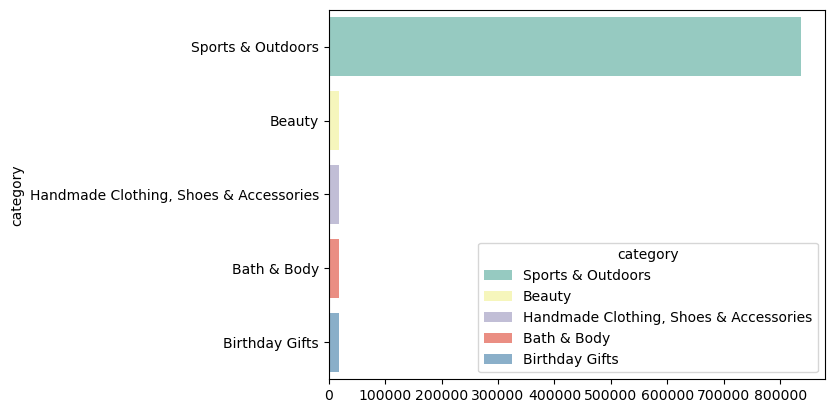

In [23]:
# 1.2 Visualisations with a subset (top 5)
frequency_table = df['category'].value_counts().head(5)
ax=sns.barplot(y=frequency_table.index, x=frequency_table.values, palette="Set3", hue=frequency_table.index, legend=True )
sns.move_legend(ax, "lower right")

In [31]:
# Pie chart
freq = pd.DataFrame(frequency_table).reset_index()
cat_subset = df[df['category'].isin(freq['category'])]

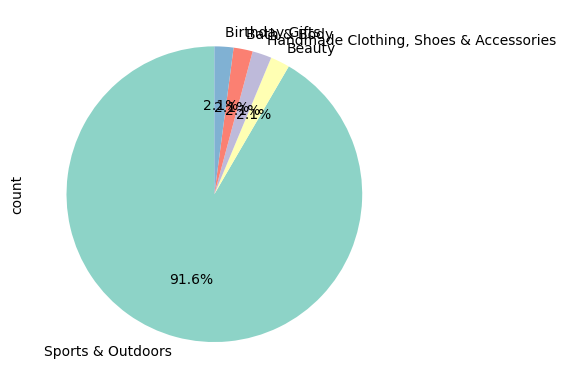

In [35]:
cat_subset['category'].value_counts().plot.pie(autopct='%.1f%%', startangle=90, colors=sns.color_palette("Set3"));
plt.show()

## The category Sports and Outdoors dominate the other categories with 91.6% of the top 5 (not the entire dataset)

### Part 2: Delving into Product Pricing

**Business Question**: How are products priced on Amazon UK, and are there specific price points or ranges that are more common?

1. **Measures of Centrality**:
    - Calculate the mean, median, and mode for the `price` of products.
    - What's the average price point of products listed? How does this compare with the most common price point (mode)?

2. **Measures of Dispersion**:
    - Determine the variance, standard deviation, range, and interquartile range for product `price`.
    - How varied are the product prices? Are there any indicators of a significant spread in prices?

3. **Visualizations**:
    - Is there a specific price range where most products fall? Plot a histogram to visualize the distribution of product prices. *If its hard to read these diagrams, think why this is, and explain how it could be solved.*.
    - Are there products that are priced significantly higher than the rest? Use a box plot to showcase the spread and potential outliers in product pricing. 

In [36]:
# 2.1 Measures of Centrality
mean_price = df['price'].mean()
median_price = df['price'].median()
mode_price = df['price'].mode()[0]

mean_price, median_price, mode_price

(np.float64(89.24380943923661), 19.09, np.float64(9.99))

### The average price point of products listed is 89 dollars. The main price (mode) is only 9.99 dollars. This means that a lot of products are 9.99 doollars and there are also products with really high prices.

In [40]:
# 2.2 Measures of Dispersion
variance_price = df['price'].var()
std_dev_price = df['price'].std()
min_price = df['price'].min()
max_price = df['price'].max()
range_price = max_price - min_price
interquartile_price = df['price'].quantile([0.25,0.75])

variance_price, std_dev_price, min_price, max_price, range_price, interquartile_price

(119445.48532256528,
 345.60886175352226,
 0.0,
 100000.0,
 100000.0,
 0.25     9.99
 0.75    45.99
 Name: price, dtype: float64)

The product prices varied a lot: variance of 119445 and standard deviation: 345.6 dollars while the interquartile is between 9.99 dollars and 45.99 dollars 
The standar deviation shows a significant spread in prices,considering mean is 89 dollars

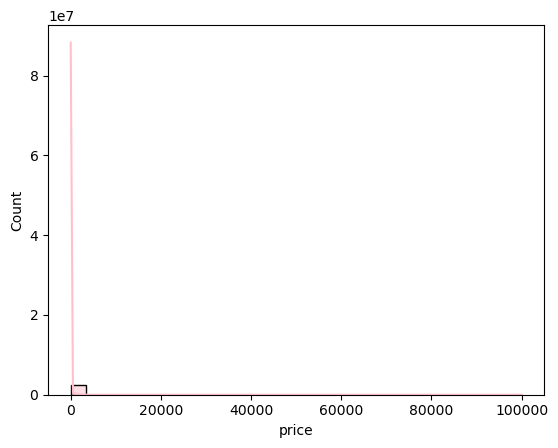

In [41]:
# 2.3 Visualisations
fig, axes = plt.subplots()
sns.histplot(df['price'], kde=True, bins=30, color="pink", ax=axes);
plt.show()

### The histogram with all the prices is not readable due to outliers with high values. To adresse this issue, we can keep only values that are the most representative, meaning between the limits of the interquartile (0.25 and 0.75)

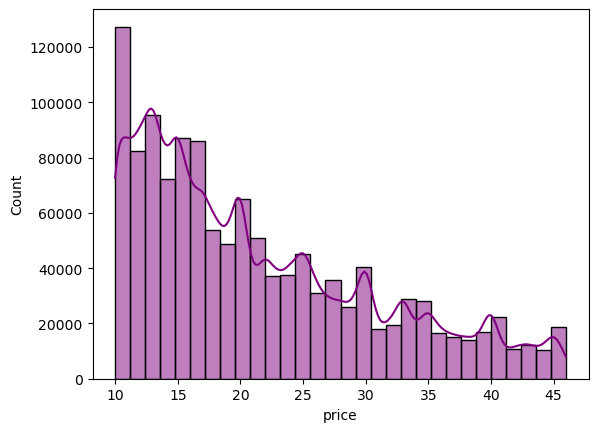

In [43]:
# improved visualization
filtered = df[(df['price'] >= 9.99) & (df['price'] <= 45.99)]
fig, axes = plt.subplots()
sns.histplot(filtered['price'], kde=True, bins=30, color="purple", ax=axes);
plt.show()

### Part 3: Unpacking Product Ratings

**Business Question**: How do customers rate products on Amazon UK, and are there any patterns or tendencies in the ratings?

1. **Measures of Centrality**:
    - Calculate the mean, median, and mode for the `rating` of products.
    - How do customers generally rate products? Is there a common trend?

2. **Measures of Dispersion**:
    - Determine the variance, standard deviation, and interquartile range for product `rating`.
    - Are the ratings consistent, or is there a wide variation in customer feedback?

3. **Shape of the Distribution**:
    - Calculate the skewness and kurtosis for the `rating` column. 
    - Are the ratings normally distributed, or do they lean towards higher or lower values?

4. **Visualizations**:
    - Plot a histogram to visualize the distribution of product ratings. Is there a specific rating that is more common?

In [45]:
# 3.1 Measures of Centrality
mean_rating = df['stars'].mean()
median_rating = df['stars'].median()
mode_rating = df['stars'].mode()[0]

mean_rating, median_rating, mode_rating

(np.float64(2.152836472966066), 0.0, np.float64(0.0))

### Customers generally don't rate the product (mode = 0)  confirmed by the median (0). However, the mean is 2.1, indicating customers assess with good ratings when they do it.

In [46]:
# 3.2 Measures of Dispersion
variance_rating = df['stars'].var()
std_dev_rating = df['stars'].std()
interquartile_rating = df['stars'].quantile([0.25,0.75])

variance_rating,std_dev_rating,interquartile_rating

(4.81743402976196,
 2.1948653785054697,
 0.25    0.0
 0.75    4.4
 Name: stars, dtype: float64)

### There is a wide variation in customers feedback as 50% (median above) of ratings were noted 0, and 75% of the ratings are under 4.4. This means that 25% of the ratings are noted. The standard deviation is 2.1 stars, identical to the mean, with indicates that the dispersion is really variable (mean value = sd value)

In [47]:
# 3.3 Shape of distribution
skewness_rating = df['stars'].skew()
kurtosis_rating = df['stars'].kurtosis()

skewness_rating, kurtosis_rating

(np.float64(0.08120735761080881), np.float64(-1.9260061280432994))

###  The ratings lean towards higher and lower values: this is highlighted by the skewness of 0.08 indicating a symetric shape. The negative kurtosis seems to report no extreme values and relatively flat whose individuals are not concentrated around the mean.

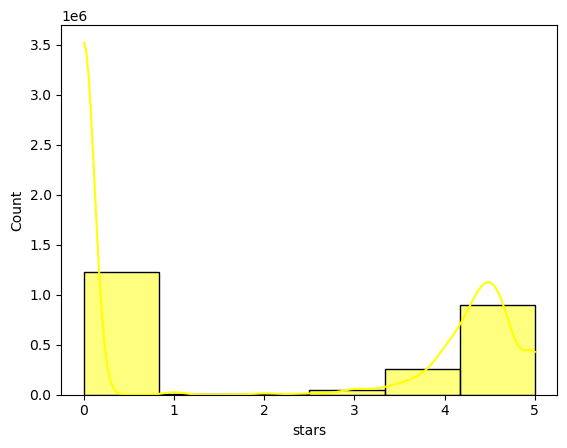

In [51]:
# 3.4 Visualzations
fig, axes = plt.subplots()
sns.histplot(df['stars'], kde=True, bins=6, color="yellow", ax=axes);
plt.show()

### The specific range for ratings, when there is a rating (out of 0) is usually between  4 and 5. This may suggest that the customers prove a real good feedback, as 5 stars is the maximum value.

### Business centric report - Product Categories, Pricing and Customer Ratings

## 1. Product Category Distribution

The top five product categories identified in the dataset, listed in descending order, are:

Sports & Outdoors

Beauty

Handmade Clothing, Shoes & Accessories

Bath & Body

Birthday Gifts

Among these categories, Sports & Outdoors largely dominates, representing 91.6% of the products within the top five categories (though not the entire dataset). This strong concentration suggests that the platform or marketplace is particularly oriented toward sports-related products and outdoor activities.

## 2. Product Pricing Analysis

The average price of listed products is $89, while the most frequent price (mode) is $9.99.

This indicates a high price dispersion within the dataset:

A large number of products are priced at $9.99, suggesting a pricing strategy.

At the same time, there are several products with very high prices, which increases the overall average.

When visualizing the price distribution using a histogram, extreme price outliers make the distribution difficult to interpret. To address this issue, it is more appropriate to focus on the interquartile range (IQR), keeping values between the 25th percentile (Q1: $9.99) and 75th percentile (Q3: $45.99). This approach highlights the most representative prices while reducing the distortion caused by extreme values.

## 3. Customer Rating Behavior

Customer engagement in terms of ratings appears relatively low.

The mode of ratings is 0, meaning most customers do not rate the products.

This observation is confirmed by the median value, which is also 0.

However, when customers do provide ratings, the evaluation tends to be positive. This is reflected by the mean rating of 2.1 stars, indicating that customers generally give good ratings when they choose to rate a product.

## 4. Variability in Customer Feedback

Customer feedback shows significant variability:

50% of the ratings are equal to 0 (median = 0).

75% of the ratings are below 4.4 stars, meaning that only 25% of ratings are between 0 (50%) and this threshold.

The standard deviation is 2.1 stars, which is equal to the mean rating. This indicates a high dispersion of ratings, suggesting that customer evaluations vary widely.

## 5. Distribution Shape of Ratings

The statistical distribution of ratings presents the following characteristics:

Skewness = 0.08, which indicates a nearly symmetric distribution. Ratings are relatively balanced between lower and higher values.

Negative kurtosis suggests a flatter distribution, meaning that observations are more spread out and not strongly concentrated around the mean.

This pattern indicates that extreme rating values are relatively uncommon.

### Conclusion

The analysis highlights three main insights:

The Sports & Outdoors category strongly dominates the dataset.

Product pricing shows significant dispersion, with many low-priced items ($9.99) alongside high-value products.

Customer rating participation is low, but when customers do rate products, their evaluations tend to be positive, though highly variable.